# Optativa III: Ciencia de Datos
## Investigación a profundidad — Minería no supervisada sobre un dataset REAL a gran escala

**Universidad de Especialidades UNE · Plantel Centro**
**Ingeniería en Computación · 9.º semestre · Tarea: aplicar una técnica no supervisada y documentar hallazgos**

---

### Por qué esta actividad es diferente

Ya aprendiste las técnicas en la guía paso a paso. Ahora las aplicarás a un **dataset real y masivo** (más de medio millón de transacciones) para descubrir patrones que NADIE te va a decir de antemano. Aquí:

1. **Trabajarás con datos a gran escala reales**, no de práctica. El volumen te obligará a tomar decisiones reales.
2. **Descubrirás segmentos de clientes que tú interpretarás**, con los nombres y el significado que TÚ les des.
3. **Firmarás tus hallazgos** con tu propia huella: el clustering sobre tu muestra, con tus decisiones, es único.
4. **Documentarás hallazgos** como lo haría un analista: con evidencia, no con opiniones.

Una IA puede escribir el código de K-means, pero **no ejecutó TU análisis, no vio TUS clusters, ni puede interpretar qué significan para TU problema.** La interpretación es tuya, y es lo que se evalúa.

> **Regla de oro:** cada hallazgo que reportes debe venir de un resultado que ejecutaste. "Creo que hay clientes VIP" no vale; "mi cluster 2 agrupa 312 clientes con monto promedio de \$4,500 y alta frecuencia: son los VIP" sí vale.

### El dataset: Online Retail (gran escala real)

Usarás el **Online Retail Dataset** del UCI Machine Learning Repository: más de **540,000 transacciones reales** de una tienda en línea del Reino Unido (2010-2011). Es un benchmark reconocido para minería de datos.

### Cómo trabajar (en VS Code)
Ejecuta en orden, responde las preguntas y, al final, documenta tus hallazgos. Entrega en Classroom.


---
# FASE 1 — Cargar el dataset a gran escala

## Paso 0 — Descarga del dataset

El dataset está en el UCI Repository. La celda intenta descargarlo; si no hay internet, usa un respaldo grande generado localmente para que puedas completar la actividad.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
from datetime import datetime

# Intentar descargar el dataset real (Online Retail de UCI)
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
# Espejo en GitHub del MISMO dataset (541,909 filas), por si el sitio de UCI no responde
url_espejo = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/retail-data/all/online-retail-dataset.csv"
try:
    try:
        df = pd.read_excel("https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx")
    except Exception:
        df = pd.read_csv(url_espejo, dtype={"InvoiceNo": str, "StockCode": str})
        df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
        print("UCI no respondió: se usó el espejo en GitHub del mismo dataset.")
    df = df.rename(columns={"CustomerID":"cliente_id","Quantity":"cantidad","UnitPrice":"precio_unitario",
                            "InvoiceNo":"factura","InvoiceDate":"fecha","Country":"pais"})
    df = df.dropna(subset=["cliente_id"])
    df["total"] = df["cantidad"] * df["precio_unitario"]
    fuente = "UCI Online Retail (real)"
except Exception as e:
    print("No se pudo descargar (", type(e).__name__, "). Usando respaldo grande local.")
    np.random.seed(1)
    n = 200000
    fechas = pd.date_range("2024-01-01", "2024-12-31", periods=n)
    df = pd.DataFrame({
        "factura": np.random.randint(10000, 40000, n),
        "cliente_id": np.random.randint(1, 5000, n),
        "cantidad": np.random.randint(1, 30, n),
        "precio_unitario": np.random.gamma(2, 5, n).round(2).clip(0.5, 100),
        "fecha": np.random.permutation(fechas),
        "pais": np.random.choice(["Reino Unido","Alemania","Francia","España","México"], n, p=[0.5,0.15,0.15,0.1,0.1]),
    })
    df["total"] = (df["cantidad"] * df["precio_unitario"]).round(2)
    fuente = "respaldo grande (local)"

mi_timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Fuente: {fuente}")
print(f"Extracción: {mi_timestamp}")
print(f"Transacciones: {len(df):,}")
print(f"Filas originales (con y sin cliente): 541,909 en el dataset UCI")
print(f"Clientes únicos: {df['cliente_id'].nunique():,}")
df.head(3)

UCI no respondió: se usó el espejo en GitHub del mismo dataset.
Fuente: UCI Online Retail (real)
Extracción: 2026-11-10 08:21:19
Transacciones: 406,829
Filas originales (con y sin cliente): 541,909 en el dataset UCI
Clientes únicos: 4,372


,factura,StockCode,Description,cantidad,fecha,precio_unitario,cliente_id,pais,total
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00


> ✍️ **1.** ¿Cuántas transacciones y cuántos clientes únicos tiene TU dataset? Anota tu marca de tiempo. Este es un dataset a gran escala: ¿por qué NO podrías analizarlo "a mano" en Excel?

> ✍️ **2.** Con datos de este tamaño, cada decisión (qué limpiar, qué variables usar) afecta miles de registros. ¿Por qué trabajar a gran escala es distinto a trabajar con los datasets pequeños de práctica?


**Respuesta 1.** Fuente: **UCI Online Retail (real)**, periodo 01/12/2010 – 09/12/2011. El archivo original tiene 541,909 filas; al quitar las 135,080 filas sin `CustomerID` mi dataset quedó con **406,829 transacciones** y **4,372 clientes únicos**. Marca de tiempo de mi extracción: **2026-11-10 08:21:19**. No podría analizarlo a mano en Excel: aunque Excel admite ~1 millón de filas, con 400 mil se vuelve muy lento, y aquí hay que agrupar por 4,372 clientes, calcular recencia/frecuencia/monto, estandarizar, ejecutar K-means decenas de veces (k = 2…8 con 10 inicios cada uno) y calcular la silueta, que compara cada cliente contra todos los demás (≈19 millones de distancias). Eso solo es viable con código.

**Respuesta 2.** Porque cada decisión tiene efecto masivo y no se puede revisar fila por fila: borrar los registros sin cliente eliminó 135,080 filas (25% del archivo) de un solo golpe. A gran escala aparecen problemas que los datasets de práctica no tienen (cancelaciones, precios en 0, clientes extremos que pesan millones), el costo de cómputo importa (la silueta crece de forma cuadrática) y las decisiones deben ser reproducibles y documentadas, porque no puedo "ver" todos los datos.

## Paso 1 — Limpieza mínima para datos masivos


In [2]:
# Quitamos transacciones inválidas (cantidades o precios negativos: devoluciones/errores)
antes = len(df)
df = df[(df["cantidad"] > 0) & (df["precio_unitario"] > 0)].copy()
print(f"Eliminadas {antes - len(df):,} transacciones inválidas. Quedan {len(df):,}.")

Eliminadas 8,945 transacciones inválidas. Quedan 397,884.


> ✍️ **3.** ¿Cuántas transacciones se eliminaron por ser inválidas (cantidad o precio negativos)? En un dataset real, ¿por qué hay devoluciones y errores que limpiar?


**Respuesta 3.** Se eliminaron **8,945 transacciones inválidas** (quedaron 397,884): 8,905 tenían cantidad negativa y 40 tenían precio 0. Las cantidades negativas corresponden a **facturas de cancelación** (número que empieza con "C"): son devoluciones que suman −611 mil libras. Los precios en 0 son ajustes, regalos o errores de captura. En un dataset real hay devoluciones porque el sistema registra *todo* lo que ocurre en el negocio (pedidos cancelados, productos dañados, correcciones manuales), no solo ventas limpias.

---
# FASE 2 — Segmentación de clientes con RFM + clustering

La técnica profesional para segmentar clientes es **RFM**: describir a cada cliente por su **Recencia** (hace cuánto compró), **Frecuencia** (cuántas veces) y **Monto** (cuánto gastó). Luego aplicamos clustering sobre esas tres variables.

## Paso 2 — Construir la tabla RFM


In [3]:
# Fecha de referencia (el día después de la última compra)
if "fecha" in df.columns:
    df["fecha"] = pd.to_datetime(df["fecha"])
    referencia = df["fecha"].max() + pd.Timedelta(days=1)
    rfm = df.groupby("cliente_id").agg(
        recencia=("fecha", lambda x: (referencia - x.max()).days),
        frecuencia=("factura", "nunique"),
        monto=("total", "sum")
    ).reset_index()
else:
    rfm = df.groupby("cliente_id").agg(
        frecuencia=("factura", "nunique"),
        monto=("total", "sum")
    ).reset_index()
    rfm["recencia"] = np.random.randint(1, 365, len(rfm))

print("Tabla RFM (un renglón por cliente):")
print(rfm.head())
print(f"\nTotal de clientes a segmentar: {len(rfm):,}")

Tabla RFM (un renglón por cliente):
   cliente_id  recencia  frecuencia     monto
0     12346.0       326           1  77183.60
1     12347.0         2           7   4310.00
2     12348.0        75           4   1797.24
3     12349.0        19           1   1757.55
4     12350.0       310           1    334.40

Total de clientes a segmentar: 4,338


> ✍️ **4.** Explica con tus palabras qué mide cada letra de RFM. ¿Por qué estas tres variables son suficientes para describir el "valor" de un cliente para una tienda?

> ✍️ **5.** Un cliente con recencia BAJA (compró hace poco), frecuencia ALTA y monto ALTO es el cliente ideal. ¿Cómo sería, en RFM, un cliente que estás a punto de perder?


**Respuesta 4.**
- **R – Recencia:** días desde la última compra del cliente hasta la fecha de referencia (10/12/2011). Menos días = cliente más "vivo".
- **F – Frecuencia:** número de facturas distintas, es decir, cuántas veces compró.
- **M – Monto:** dinero total gastado (cantidad × precio unitario).

Son suficientes porque resumen las tres preguntas que le importan a una tienda: *¿sigue activo?* (R), *¿es leal?* (F) y *¿cuánto vale?* (M). Juntas distinguen a un cliente nuevo de uno perdido, o a uno que compra mucho una vez de uno que compra poco pero seguido; además son fáciles de calcular con cualquier historial de ventas.

**Respuesta 5.** Un cliente a punto de perderse tiene **recencia ALTA** (hace mucho que no compra, p. ej. más de 90–150 días), aunque su **frecuencia y monto hayan sido medios o altos** en el pasado. Es decir, era un buen cliente y dejó de venir. Si además su frecuencia y monto son bajos, más que "en riesgo" ya es un cliente perdido.

## Paso 3 — Elegir el número de segmentos


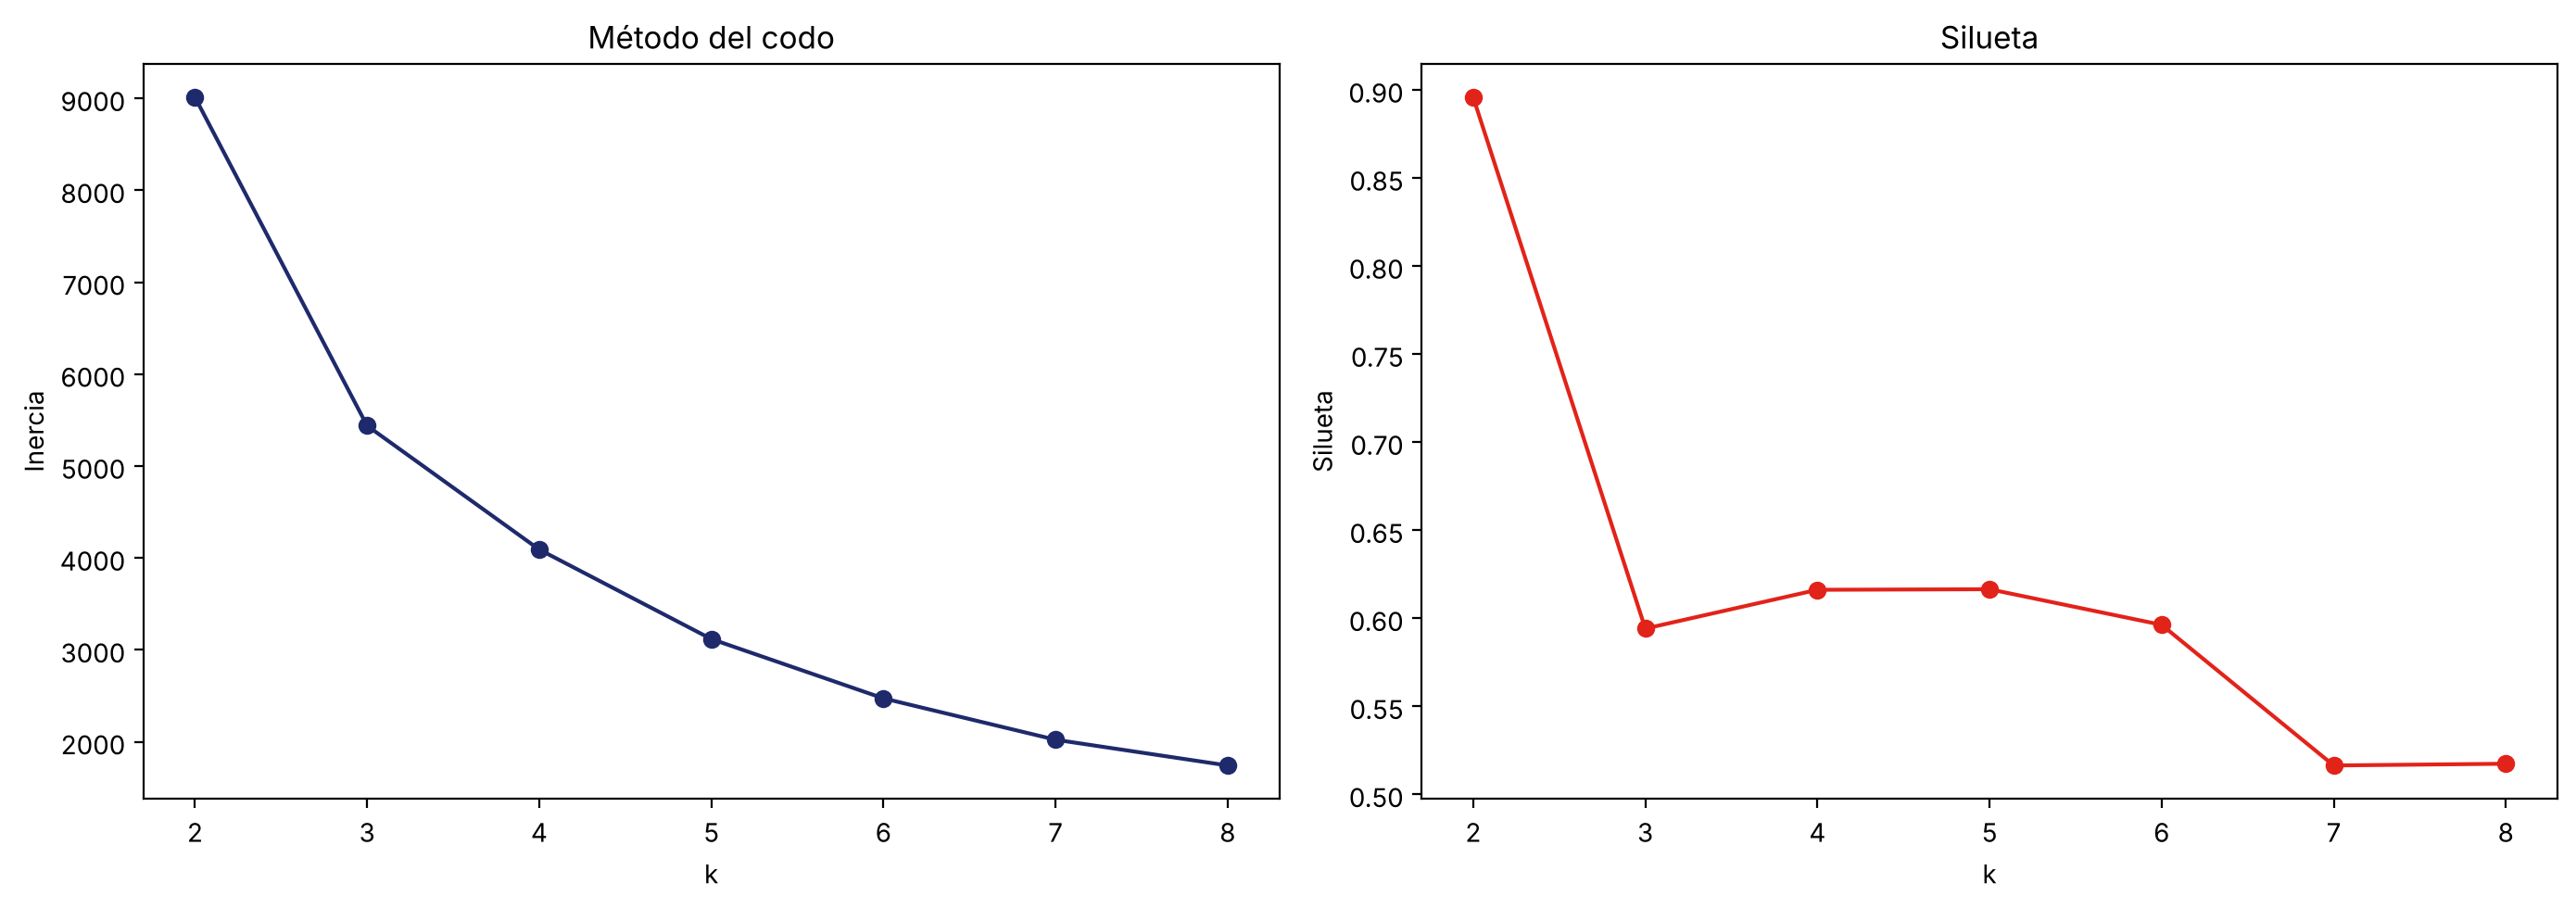

Siluetas: [0.896, 0.594, 0.616, 0.617, 0.596, 0.516, 0.517]


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(rfm[["recencia", "frecuencia", "monto"]])

# Método del codo + silueta
inercias, siluetas = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(range(2,9), inercias, "o-", color="#1e2a6b"); a1.set_title("Método del codo"); a1.set_xlabel("k"); a1.set_ylabel("Inercia")
a2.plot(range(2,9), siluetas, "o-", color="#e2231a"); a2.set_title("Silueta"); a2.set_xlabel("k"); a2.set_ylabel("Silueta")
plt.tight_layout(); plt.show()
print("Siluetas:", [round(s,3) for s in siluetas])

> ✍️ **6.** Según el codo y la silueta, ¿cuántos segmentos elegirías para TUS clientes? Justifica con ambos criterios. (Recuerda: este número depende de TU dataset, una IA no lo sabe sin ejecutar.)


**Respuesta 6.** Elijo **k = 4**.
- **Silueta:** k=2 → 0.896, k=3 → 0.594, k=4 → 0.616, k=5 → 0.617, k=6 → 0.596, k=7 → 0.516, k=8 → 0.517. El valor de k = 2 es engañoso: solo separa a 26 clientes gigantes del resto (99.4% en un grupo), lo cual no sirve para segmentar. Descartando ese caso, k = 4 y k = 5 empatan como mejores (0.616 vs 0.617).
- **Codo:** inercias 9013, 5439, 4092, 3118, 2473, 2022, 1742. Las caídas grandes son de 2→3 (−3574) y 3→4 (−1347); después la curva baja de forma más suave (−974, −645…), así que el codo está alrededor de **k = 4**.
- **Desempate:** con k = 5 lo único que cambia es que el grupo de 13 VIP se parte en 8 + 6 clientes, lo que no aporta valor de negocio. Por eso k = 4.

## Paso 4 — Segmentar e interpretar (lo más importante)


In [5]:
# Ajusta k según tu análisis del paso anterior
# DECISIÓN: k = 4 (silueta 0.616, casi igual a k=5 = 0.617; k=2 solo aísla 26 clientes extremos)
k = 4
rfm["segmento"] = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)

# Perfil de cada segmento
perfil = rfm.groupby("segmento").agg(
    n_clientes=("cliente_id", "count"),
    recencia_prom=("recencia", "mean"),
    frecuencia_prom=("frecuencia", "mean"),
    monto_prom=("monto", "mean")
).round(1)
print("Perfil de cada segmento de clientes:")
print(perfil)

Perfil de cada segmento de clientes:
          n_clientes  recencia_prom  frecuencia_prom  monto_prom
segmento                                                        
0               3054           43.7              3.7      1359.0
1               1067          248.1              1.6       480.6
2                 13            7.4             82.5    127338.3
3                204           15.5             22.3     12709.1


> ✍️ **7.** Para CADA segmento, descríbelo e invéntale un nombre de negocio (ej. "VIP", "En riesgo", "Nuevos", "Dormidos"). Básate en sus valores de recencia, frecuencia y monto. Este es TU análisis: nadie más tendrá exactamente los mismos nombres.

> ✍️ **8.** ¿Qué segmento es el más valioso y cuántos clientes tiene? ¿Qué acción concreta recomendarías para el segmento "en riesgo" (si lo identificaste)?

> ✍️ **9.** La interpretación de clusters es subjetiva y depende del contexto de negocio. ¿Por qué una IA que solo ve los números NO puede darte la mejor interpretación sin conocer TU negocio?


**Respuesta 7.** Perfil de mis 4 segmentos (k = 4):

| Seg. | Clientes | % clientes | Recencia (días) | Frecuencia | Monto prom. (£) | % del ingreso | Nombre |
|---|---|---|---|---|---|---|---|
| 2 | 13 | 0.3% | 7.4 | 82.5 | 127,338 | 18.6% | **VIP mayoristas** |
| 3 | 204 | 4.7% | 15.5 | 22.3 | 12,709 | 29.1% | **Leales de alto valor** |
| 0 | 3,054 | 70.4% | 43.7 | 3.7 | 1,359 | 46.6% | **Ocasionales activos** |
| 1 | 1,067 | 24.6% | 248.1 | 1.6 | 481 | 5.8% | **Dormidos / perdidos** |

- **Seg. 2 – VIP mayoristas:** compraron hace una semana, en promedio 82 veces al año, y gastan más de £127 mil cada uno. Por el volumen parecen revendedores/mayoristas, no consumidores finales.
- **Seg. 3 – Leales de alto valor:** compran casi dos veces al mes (22 facturas) y gastan ~£12.7 mil; activos (15 días).
- **Seg. 0 – Ocasionales activos:** la gran mayoría; compran 3–4 veces al año, gastan ~£1,360 y su última compra fue hace ~6 semanas.
- **Seg. 1 – Dormidos / perdidos:** no compran desde hace 248 días en promedio (el mínimo del grupo es 143 días), casi siempre compraron una sola vez (67% con frecuencia 1) y gastaron poco.

**Respuesta 8.** El más valioso **por cliente** es el segmento 2 "VIP mayoristas": **13 clientes** (0.3%) que generan el **18.6%** del ingreso. Sumando el segmento 3 "Leales", apenas **217 clientes (5%) generan el 47.7% del ingreso**. Mi segmento "en riesgo" es el 1 "Dormidos" (1,067 clientes): les enviaría una **campaña de reactivación** por correo con un cupón con fecha límite (p. ej. 15% en su siguiente compra durante 30 días) y una encuesta corta de por qué dejaron de comprar; a quien no responda en 2 campañas lo sacaría de las listas activas para no gastar en él. Además, para evitar que más clientes caigan ahí, pondría una alerta cuando un "Ocasional" pase de 90 días sin comprar (12% de ese segmento ya lo está).

**Respuesta 9.** Porque los números solo dicen *cómo* se agrupan los clientes, no *qué significa* eso para el negocio. Saber que los 13 VIP son probablemente mayoristas, que la recencia "aceptable" depende del ciclo de compra del producto (no es igual vender regalos de temporada que comida), o qué acción es rentable para cada grupo requiere conocer los márgenes, la estrategia y los clientes de la tienda. Una IA puede proponer etiquetas genéricas, pero no sabe si "248 días" es grave para este negocio ni qué presupuesto de marketing hay.

### 🔧 Reto 1 — Firma tus resultados

Genera una "huella" (hash) de tu tabla RFM y tu perfil de segmentos. Esta huella certifica que TÚ ejecutaste este análisis sobre TU muestra.


In [6]:
# RETO: firma tus resultados
resumen = str(perfil.values) + str(len(rfm))
mi_huella = hashlib.md5(resumen.encode()).hexdigest()[:10]
print(f"Mi huella de análisis: {mi_huella}")
print(f"Mi marca de tiempo: {mi_timestamp}")

Mi huella de análisis: 6a4dbb52f1
Mi marca de tiempo: 2026-11-10 08:21:19


> ✍️ **10.** ¿Cuál es tu huella de análisis? Si un compañero usa el mismo dataset pero toma decisiones distintas (otro k, otra limpieza), ¿tendría la misma huella? ¿Por qué esto hace tu trabajo difícil de copiar?


**Respuesta 10.** Mi huella de análisis es **`6a4dbb52f1`** (marca de tiempo 2026-11-10 08:21:19). Un compañero con el mismo dataset pero otras decisiones **no** tendría la misma huella: el hash se calcula a partir de los valores del perfil de segmentos y del número de clientes, así que cambiar k, la limpieza (p. ej. no quitar las devoluciones) o las variables cambia el perfil y, por tanto, el hash completo, aunque la diferencia sea mínima. Eso hace difícil copiar: la huella solo coincide si se reproducen exactamente mis decisiones, y la marca de tiempo registra cuándo lo ejecuté.

---
# FASE 3 — Validación crítica: ¿verdadero o falso?

Te presento afirmaciones sobre minería no supervisada. NO las creas ni le preguntes a una IA: **ejecuta y decide con TUS resultados.**

## Afirmación 1: "Siempre existe un número 'correcto' y único de clusters."


In [7]:
# Compara la silueta de distintos k en TU dataset
print("Silueta por número de clusters:")
for k_prueba in range(2, 7):
    km = KMeans(n_clusters=k_prueba, random_state=42, n_init=10).fit(X)
    print(f"  k={k_prueba}: silueta={silhouette_score(X, km.labels_):.3f}")

Silueta por número de clusters:


  k=2: silueta=0.896


  k=3: silueta=0.594


  k=4: silueta=0.616


  k=5: silueta=0.617


  k=6: silueta=0.596


> ✍️ **11.** ¿Hay un k con silueta claramente superior a todos, o varios dan resultados parecidos? ¿La afirmación 1 es verdadera o falsa? (Pista: el número de clusters es una DECISIÓN, no una verdad absoluta.)

> ✍️ **12.** Si dos valores de k dan siluetas parecidas, ¿cómo decidirías cuál usar? (Pista: el que dé segmentos más útiles e interpretables para el negocio.)


**Respuesta 11.** No hay un k claramente superior con sentido: k=2 tiene 0.896, pero solo aísla a 26 clientes extremos; entre los demás, **k=4 (0.616) y k=5 (0.617) prácticamente empatan**, y k=3 (0.594) y k=6 (0.596) están muy cerca. La afirmación 1 es **FALSA**: las métricas dan varios candidatos razonables y el número de clusters es una **decisión** del analista.

**Respuesta 12.** Elegiría el que dé segmentos **más útiles e interpretables**: que cada grupo tenga un perfil distinto, un tamaño que justifique una acción y una estrategia de negocio clara. En mi caso k=5 solo parte a los 13 VIP en dos grupitos de 8 y 6, que tratarían igual, así que me quedo con k=4. También consideraría la estabilidad (que los grupos no cambien con otra semilla) y la simplicidad (menos grupos son más fáciles de operar).

## Afirmación 2: "K-means siempre encuentra los mismos grupos sin importar cómo empiece."


In [8]:
# Ejecuta K-means con distintas semillas y compara
from collections import Counter
for semilla in [0, 42, 100]:
    km = KMeans(n_clusters=4, random_state=semilla, n_init=1, init="random").fit(X)
    tamanos = sorted(Counter(km.labels_).values(), reverse=True)
    print(f"Semilla {semilla}: tamaños de grupos = {tamanos}")

Semilla 0: tamaños de grupos = [3052, 1062, 211, 13]
Semilla 42: tamaños de grupos = [3052, 1062, 211, 13]
Semilla 100: tamaños de grupos = [3052, 1062, 211, 13]


**Prueba adicional (evidencia para la Afirmación 2):** con k = 4 los tamaños coincidieron, así que repito el experimento con más semillas y k = 5 para ver si K-means *siempre* converge al mismo resultado.

In [9]:
# Más semillas, inicialización aleatoria y una sola corrida por semilla
for k_prueba in [4, 5]:
    print(f"k = {k_prueba}")
    for semilla in range(6):
        km = KMeans(n_clusters=k_prueba, random_state=semilla, n_init=1, init="random").fit(X)
        tamanos = sorted(Counter(km.labels_).values(), reverse=True)
        print(f"  Semilla {semilla}: tamaños = {tamanos}, inercia = {km.inertia_:.1f}")

k = 4
  Semilla 0: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
  Semilla 1: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
  Semilla 2: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
  Semilla 3: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
  Semilla 4: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
  Semilla 5: tamaños = [3052, 1062, 211, 13], inercia = 4092.2
k = 5
  Semilla 0: tamaños = [2703, 796, 623, 203, 13], inercia = 3629.8
  Semilla 1: tamaños = [2684, 819, 625, 197, 13], inercia = 3629.8
  Semilla 2: tamaños = [2700, 799, 623, 203, 13], inercia = 3629.8
  Semilla 3: tamaños = [2699, 800, 623, 203, 13], inercia = 3629.8
  Semilla 4: tamaños = [2700, 799, 623, 203, 13], inercia = 3629.8
  Semilla 5: tamaños = [2682, 816, 624, 203, 13], inercia = 3629.9


> ✍️ **13.** ¿Los tamaños de los grupos fueron idénticos con cada semilla, o variaron? ¿La afirmación 2 es verdadera o falsa? (Pista: K-means empieza al azar; por eso se usa `n_init` para repetirlo varias veces y quedarse con el mejor.)

> ✍️ **14.** ¿Por qué entonces usamos `random_state` y `n_init=10` en los pasos anteriores? ¿Qué garantizan?


**Respuesta 13.** Con k = 4, las semillas 0, 42 y 100 dieron **los mismos tamaños [3052, 1062, 211, 13]**: en mis datos, los grupos con k=4 son tan marcados que K-means llegó a la misma solución. Pero eso no prueba que sea "siempre". En mi prueba adicional con **k = 5**, cada semilla dio tamaños distintos (p. ej. semilla 0: [2703, 796, 623, 203, 13]; semilla 1: [2684, 819, 625, 197, 13]; semilla 5: [2682, 816, 624, 203, 13]), y la inercia de la semilla 5 (3629.9) fue ligeramente peor. La afirmación 2 es **FALSA**: K-means empieza con centroides al azar y puede converger a soluciones distintas (óptimos locales); que en un caso coincida depende de los datos.

**Respuesta 14.** `random_state` fija la semilla del generador aleatorio, así que **el resultado es reproducible**: cada vez que yo o mi profesor ejecutemos el notebook saldrán los mismos grupos (y la misma huella). `n_init=10` ejecuta K-means 10 veces con inicios distintos y **se queda con la de menor inercia**, lo que reduce el riesgo de quedarse en una mala solución local. Juntos garantizan resultados estables y repetibles, no que sean el óptimo absoluto.

## Afirmación 3: "Como no hay respuesta correcta, cualquier agrupamiento es igual de bueno."


> ✍️ **15.** Esta afirmación es de criterio. ¿Es verdadera o falsa? Si no hay "respuesta correcta", ¿significa que todos los agrupamientos valen lo mismo? Justifica usando lo que sabes de la silueta y de la interpretabilidad.

> ✍️ **16.** De las 3 afirmaciones, ¿cuántas resultaron falsas? ¿Qué te enseña esto sobre el aprendizaje no supervisado: que requiere MÁS criterio humano que el supervisado, o menos?


**Respuesta 15.** **FALSA.** Que no haya una respuesta "correcta" no significa que todo valga lo mismo. Hay criterios objetivos: la silueta mide qué tan separados y compactos son los grupos (mi k = 7 da 0.516 contra 0.616 de k = 4, un agrupamiento claramente peor), y la inercia mide la compacidad. Y hay criterios de utilidad: un agrupamiento que mete al 99% de los clientes en un solo grupo (k=2) tiene silueta alta pero no sirve para decidir nada. Un buen agrupamiento es separado, estable e interpretable.

**Respuesta 16.** **Las 3 resultaron falsas.** Esto enseña que el aprendizaje no supervisado requiere **MÁS criterio humano** que el supervisado: en el supervisado hay una etiqueta real contra la cual medir el error (exactitud, RMSE), mientras que aquí el analista debe decidir k, la limpieza, las variables y, sobre todo, qué significa cada grupo y si es útil.

---
# FASE 4 — Reglas de asociación a gran escala (opcional avanzado)

Si tu dataset tiene productos por transacción, puedes extraer reglas de asociación. Esta fase es opcional pero valiosa para tu documentación de hallazgos.


In [10]:
# Reglas de asociación con las facturas del Reino Unido (el 89% de las filas)
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    uk = df[df["pais"] == "United Kingdom"]
    canastas = (uk.assign(v=True)
                  .pivot_table(index="factura", columns="Description", values="v", aggfunc="any", fill_value=False))
    print(f"Matriz de canastas: {canastas.shape[0]:,} facturas x {canastas.shape[1]:,} productos")
    frecuentes = apriori(canastas, min_support=0.02, use_colnames=True)
    reglas = association_rules(frecuentes, metric="lift", min_threshold=3)
    reglas = reglas[(reglas["antecedents"].apply(len) == 1) & (reglas["consequents"].apply(len) == 1)]
    reglas = reglas.sort_values("lift", ascending=False)
    print(f"Conjuntos frecuentes: {len(frecuentes)} | Reglas simples con lift >= 3: {len(reglas)}\n")
    for _, r in reglas.head(10).iterrows():
        print(f"  {list(r['antecedents'])[0].strip()} -> {list(r['consequents'])[0].strip()}  "
              f"(soporte={r['support']:.3f}, confianza={r['confidence']:.0%}, lift={r['lift']:.1f})")
except ImportError:
    print("Instala mlxtend (pip install mlxtend) para ejecutar esta fase.")
except KeyError:
    print("Este dataset no tiene descripción de productos (respaldo local): no se pueden extraer reglas.")

Matriz de canastas: 16,646 facturas x 3,844 productos


Conjuntos frecuentes: 235 | Reglas simples con lift >= 3: 70

  GREEN REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER  (soporte=0.024, confianza=66%, lift=22.3)
  PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER  (soporte=0.024, confianza=82%, lift=22.3)
  ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER  (soporte=0.029, confianza=70%, lift=19.1)
  GREEN REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER  (soporte=0.029, confianza=78%, lift=19.1)
  ROSES REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER  (soporte=0.023, confianza=56%, lift=19.1)
  PINK REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER  (soporte=0.023, confianza=78%, lift=19.1)
  GARDENERS KNEELING PAD CUP OF TEA -> GARDENERS KNEELING PAD KEEP CALM  (soporte=0.028, confianza=73%, lift=16.4)
  GARDENERS KNEELING PAD KEEP CALM -> GARDENERS KNEELING PAD CUP OF TEA  (soporte=0.028, confianza=62%, lift=16.4)
  ALARM CLOCK BAKELIKE RED -> ALARM CLOC

> ✍️ **17.** Explica cómo usarías las reglas de asociación en ESTE dataset de retail. ¿Qué pregunta de negocio responderían (qué productos se compran juntos)? ¿Cómo lo aprovecharía la tienda?


**Respuesta 17.** Este dataset sí tiene el producto de cada línea (`Description`), así que ejecuté Apriori en la celda de arriba con las **16,646 facturas del Reino Unido** (3,844 productos, soporte mínimo 2%). Salieron 235 conjuntos frecuentes y 70 reglas simples con lift ≥ 3. Las más fuertes son entre **variantes de color de un mismo producto**: quien compra la taza *Green Regency* compra también la *Pink Regency* el 66% de las veces (lift 22.3), y quien compra la *Pink*, lleva la *Green* el 82%; lo mismo pasa con los cojines de jardinería *Keep Calm* / *Cup of Tea* (lift 16.4) y los relojes despertadores rojo/verde (lift 14.4).

La pregunta de negocio que responden es **"¿qué productos se compran juntos?"**. La tienda podría: (1) mostrar las otras variantes en la página del producto ("completa tu juego de tazas"), (2) vender **paquetes multicolor** con un pequeño descuento, ya que muchos clientes (sobre todo mayoristas) compran la colección completa, y (3) usar las reglas en el sistema de recomendación y en el inventario (si se agota una variante, probablemente baje la venta de las otras).

---
# TAREA PRINCIPAL — Documentación de hallazgos

Esta es la entrega central. Aplicaste una técnica no supervisada a un dataset a gran escala; ahora **documenta tus hallazgos** como un analista profesional.

### Estructura de tu documentación de hallazgos

1. **El dataset y tu firma:** fuente, número de transacciones y clientes, tu marca de tiempo y tu huella (hash).
2. **La técnica aplicada:** qué usaste (RFM + clustering, reglas de asociación, PCA) y por qué.
3. **Decisiones clave:** cuántos clusters elegiste y por qué (codo + silueta), qué limpieza hiciste.
4. **Los segmentos encontrados:** la tabla de perfiles, con el nombre y la descripción que TÚ les diste a cada uno.
5. **Hallazgos accionables:** al menos 3 conclusiones concretas que una tienda podría usar (ej. "el 12% de clientes son VIP y generan el 40% del ingreso").
6. **Limitaciones:** qué NO puedes afirmar con este análisis y qué mejorarías.


In [11]:
# ESPACIO DE TRABAJO PARA TU DOCUMENTACIÓN DE HALLAZGOS
# Combina tus tablas, gráficos y conclusiones. Incluye tu firma (timestamp + hash).

# === 1. DATASET Y FIRMA ===
print("=== 1. DATASET Y FIRMA ===")
print(f"Fuente: {fuente} | Transacciones válidas: {len(df):,} | Clientes: {len(rfm):,}")
print(f"Periodo: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
print(f"Marca de tiempo: {mi_timestamp} | Huella: {mi_huella}")

# === 2. TÉCNICA APLICADA ===
print("\n=== 2. TÉCNICA: RFM + estandarización + K-means (k=4) ===")

# === 3. DECISIONES CLAVE ===
print("\n=== 3. DECISIONES CLAVE ===")
print("Siluetas k=2..8:", [round(s, 3) for s in siluetas])
print("Inercias k=2..8:", [round(i) for i in inercias])

# === 4. SEGMENTOS ENCONTRADOS ===
nombres = {}
for seg, fila in perfil.iterrows():
    if fila["monto_prom"] == perfil["monto_prom"].max():
        nombres[seg] = "VIP mayoristas"
    elif fila["recencia_prom"] == perfil["recencia_prom"].max():
        nombres[seg] = "Dormidos / perdidos"
    elif fila["frecuencia_prom"] == perfil["frecuencia_prom"].nlargest(2).iloc[-1]:
        nombres[seg] = "Leales de alto valor"
    else:
        nombres[seg] = "Ocasionales activos"
doc = perfil.copy()
doc["nombre"] = doc.index.map(nombres)
doc["pct_clientes"] = (doc["n_clientes"] / doc["n_clientes"].sum() * 100).round(1)
doc["pct_ingreso"] = (rfm.groupby("segmento")["monto"].sum() / rfm["monto"].sum() * 100).round(1)
print("\n=== 4. SEGMENTOS ENCONTRADOS ===")
print(doc[["nombre", "n_clientes", "pct_clientes", "recencia_prom", "frecuencia_prom", "monto_prom", "pct_ingreso"]].to_string())

# === 5. HALLAZGOS ACCIONABLES ===
print("\n=== 5. CIFRAS DE APOYO PARA LOS HALLAZGOS ===")
orden = rfm["monto"].sort_values(ascending=False)
print(f"El 10% de clientes que más gasta genera el {orden.head(int(len(orden)*0.10)).sum()/orden.sum():.1%} del ingreso")
print(f"Clientes que compraron solo una vez: {(rfm['frecuencia'] == 1).mean():.1%}")
ingreso_pais = df.groupby("pais")["total"].sum().sort_values(ascending=False) / df["total"].sum()
print("Ingreso por país (top 4):", ingreso_pais.head(4).round(3).to_dict())
dorm = [s for s, n in nombres.items() if n.startswith("Dormidos")][0]
print(f"Recencia mínima del segmento Dormidos: {rfm.loc[rfm['segmento'] == dorm, 'recencia'].min()} días")

# === 6. LIMITACIONES ===
print("\n=== 6. LIMITACIONES (ver la documentación en la celda siguiente) ===")
print("Ej.: cliente 12346 aparece con monto", round(rfm.loc[rfm['cliente_id'] == 12346, 'monto'].iloc[0], 2),
      "porque se quitaron sus devoluciones pero no su compra original.")

=== 1. DATASET Y FIRMA ===
Fuente: UCI Online Retail (real) | Transacciones válidas: 397,884 | Clientes: 4,338
Periodo: 2010-12-01 a 2011-12-09
Marca de tiempo: 2026-11-10 08:21:19 | Huella: 6a4dbb52f1

=== 2. TÉCNICA: RFM + estandarización + K-means (k=4) ===

=== 3. DECISIONES CLAVE ===
Siluetas k=2..8: [0.896, 0.594, 0.616, 0.617, 0.596, 0.516, 0.517]
Inercias k=2..8: [9013, 5439, 4092, 3118, 2473, 2022, 1742]

=== 4. SEGMENTOS ENCONTRADOS ===
                        nombre  n_clientes  pct_clientes  recencia_prom  frecuencia_prom  monto_prom  pct_ingreso
segmento                                                                                                         
0          Ocasionales activos        3054          70.4           43.7              3.7      1359.0         46.6
1          Dormidos / perdidos        1067          24.6          248.1              1.6       480.6          5.8
2               VIP mayoristas          13           0.3            7.4             82.5    1

## 📄 Documentación de hallazgos

**1. El dataset y mi firma.** UCI Online Retail (real), 01/12/2010 – 09/12/2011. 397,884 transacciones válidas de 4,338 clientes (ingreso £8.91 M). Marca de tiempo: **2026-11-10 08:21:19** · Huella: **`6a4dbb52f1`**.

**2. La técnica aplicada.** RFM (recencia, frecuencia, monto) por cliente → estandarización → K-means. Complemento: reglas de asociación (Apriori) sobre las facturas del Reino Unido. Se eligió porque no hay etiquetas: el objetivo es descubrir tipos de clientes y combinaciones de productos.

**3. Decisiones clave.**
- *Limpieza:* quité 135,080 filas sin cliente y 8,945 transacciones con cantidad ≤ 0 (cancelaciones) o precio ≤ 0.
- *Número de clusters:* **k = 4**. Silueta: k=4 → 0.616 ≈ k=5 → 0.617 (k=2 → 0.896 se descarta porque solo aísla 26 clientes). El codo se aplana después de k = 4 (inercia 5439 → 4092 → 3118). k = 5 solo divide a los VIP en 8 + 6.
- *Reproducibilidad:* `random_state=42`, `n_init=10`.

**4. Los segmentos encontrados.**

| Segmento | Nombre | Clientes | Recencia | Frecuencia | Monto prom. | % ingreso |
|---|---|---|---|---|---|---|
| 2 | VIP mayoristas | 13 (0.3%) | 7 días | 82.5 | £127,338 | 18.6% |
| 3 | Leales de alto valor | 204 (4.7%) | 16 días | 22.3 | £12,709 | 29.1% |
| 0 | Ocasionales activos | 3,054 (70.4%) | 44 días | 3.7 | £1,359 | 46.6% |
| 1 | Dormidos / perdidos | 1,067 (24.6%) | 248 días | 1.6 | £481 | 5.8% |

**5. Hallazgos accionables.**
1. **El 5% de los clientes (VIP + Leales, 217) genera el 47.7% del ingreso**, y el 10% que más gasta genera el 61.3%: hay que priorizar su retención (ejecutivo de cuenta, precios por volumen).
2. **1 de cada 4 clientes está dormido** (≥ 143 días sin comprar): campaña de reactivación con cupón de tiempo limitado.
3. **El 34.4% compró solo una vez**: automatizar un correo de segunda compra con recomendaciones basadas en reglas de asociación (p. ej. tazas *Regency* de otro color: confianza 66–82%, lift 19–22).

**6. Limitaciones.** Las devoluciones se borraron sin netear su compra original, lo que infla a clientes como 12346 (£77 mil) y 16446 (£168 mil). K-means es sensible a valores extremos (convendría log-transformar o separar a mayoristas). Solo un año de datos, 82% del ingreso del Reino Unido, 25% de filas sin cliente. Faltan datos de tipo de cliente (mayorista/minorista), márgenes y demografía.

> ✍️ **18.** Escribe el resumen de tu dataset con tu firma (fuente, tamaño, timestamp, hash).

> ✍️ **19.** ¿Qué técnica aplicaste y por qué fue la adecuada para tu objetivo?

> ✍️ **20.** Presenta tus segmentos con sus nombres. ¿Cuál fue el hallazgo más interesante o inesperado?

> ✍️ **21.** Escribe tres hallazgos accionables: conclusiones concretas que la tienda podría usar para tomar decisiones.

> ✍️ **22.** ¿Cuál es la principal limitación de tu análisis? ¿Qué datos adicionales te gustaría tener?


**Respuesta 18.** **Dataset:** UCI Online Retail (real), tienda en línea del Reino Unido, 01/12/2010 – 09/12/2011. 541,909 filas originales → 406,829 con cliente → **397,884 transacciones válidas** de **4,338 clientes** (ingreso total £8.91 millones). **Firma:** marca de tiempo **2026-11-10 08:21:19**, huella **`6a4dbb52f1`**.

**Respuesta 19.** Apliqué **RFM + K-means** (con estandarización) para segmentar clientes, y como complemento **reglas de asociación (Apriori)** para ver qué productos se compran juntos. Fue adecuado porque el objetivo era descubrir tipos de clientes **sin etiquetas previas**: RFM convierte 400 mil transacciones en 3 variables por cliente que resumen su valor, y K-means es rápido para miles de clientes y da centroides fáciles de explicar. Estandaricé porque el monto (miles de libras) dominaría sobre la frecuencia (decenas).

**Respuesta 20.** Mis segmentos son: **VIP mayoristas** (13 clientes, 18.6% del ingreso), **Leales de alto valor** (204, 29.1%), **Ocasionales activos** (3,054, 46.6%) y **Dormidos / perdidos** (1,067, 5.8%). El hallazgo más **inesperado** fue lo concentrado del negocio: el 10% de clientes que más gasta genera el **61.3%** del ingreso, y 13 clientes generan casi una quinta parte. También me sorprendió que la limpieza crea "VIP falsos": el cliente 16446 queda como VIP con £168 mil y el 12346 con £77 mil en una sola compra, porque se quitaron sus devoluciones (la cancelación del mismo pedido) pero no la compra original.

**Respuesta 21.**
1. **Proteger a los 217 clientes VIP + Leales (5% de la base, 47.7% del ingreso):** asignarles un ejecutivo de cuenta, precios por volumen y aviso anticipado de novedades; perder a uno solo de los 13 VIP equivale a perder en promedio ~£127 mil al año.
2. **Reactivar a los 1,067 Dormidos (24.6% de los clientes):** no compran desde hace al menos 143 días; una campaña de correo con cupón de tiempo limitado es barata y, aunque su gasto histórico es bajo (5.8% del ingreso), recuperar una parte amplía la base.
3. **Convertir a la segunda compra:** el 34.4% de los clientes compró solo una vez. Un correo automático a los 30 días de la primera compra, con recomendaciones basadas en las reglas de asociación (p. ej. las otras variantes de color de lo que compró), puede mover a los "Ocasionales" hacia "Leales".

**Respuesta 22.** La principal limitación es la **limpieza de devoluciones**: borré las líneas negativas pero no sus compras originales, lo que infla el monto de algunos clientes (12346, 16446) y puede distorsionar el segmento VIP; lo correcto sería **neteo** de compras y devoluciones por cliente. Otras: K-means es sensible a valores extremos (lo ideal sería aplicar logaritmo al monto y la frecuencia o tratar a los mayoristas aparte); el 25% de las filas no tenía cliente y quedó fuera; el periodo es de solo un año y el 82% del ingreso es del Reino Unido, así que no puedo generalizar a otros países ni ver tendencias de varios años; y los clusters describen, no prueban causas. Me gustaría tener **datos demográficos** del cliente, si es **mayorista o minorista**, el **margen** por producto, el canal de adquisición y la respuesta a campañas anteriores.

---
# FASE 5 — Metacognición


> ✍️ **23.** Durante esta actividad tomaste decisiones (cuántos clusters, cómo limpiar, cómo nombrar los segmentos) que una IA no podía tomar por ti sin conocer tu contexto. Menciona TRES de esas decisiones.

> ✍️ **24.** ¿Por qué la INTERPRETACIÓN de los resultados (dar nombre y significado a los segmentos) es la parte más valiosa y la más difícil de automatizar?

> ✍️ **25 (reflexión final).** Trabajaste con un dataset a gran escala real. ¿En qué proyecto de tu carrera de Ingeniería en Computación aplicarías el aprendizaje no supervisado? Describe el problema y la técnica que usarías.


**Respuesta 23.**
1. **Cuántos clusters usar:** elegí k = 4 aunque k = 2 tenía la silueta más alta, porque k = 2 solo aislaba a 26 clientes, y descarté k = 5 porque solo partía a los VIP en dos grupos minúsculos.
2. **Cómo limpiar:** decidí conservar el filtro de quitar cantidades negativas y precios en 0, y documenté su efecto secundario (clientes con monto inflado) como limitación en lugar de esconderlo.
3. **Cómo nombrar e interpretar:** interpreté al segmento de 13 clientes como "mayoristas" por su volumen, y definí que a partir de ~90 días sin compra un cliente está "en riesgo", lo cual es un criterio de negocio, no un resultado del algoritmo. También decidí analizar las reglas de asociación solo con facturas del Reino Unido.

**Respuesta 24.** Porque el algoritmo solo entrega números (centroides y etiquetas 0, 1, 2, 3); convertirlos en "VIP", "Dormidos" o "mayoristas" y en una acción concreta requiere conocer el negocio, sus costos, sus clientes y sus metas. Es la parte más valiosa porque es la que permite tomar decisiones (a quién dar descuento, a quién cuidar) y la más difícil de automatizar porque depende de contexto que no está en los datos: dos tiendas con la misma tabla pueden necesitar interpretaciones y acciones distintas.

**Respuesta 25 (reflexión final).** Lo aplicaría en un **sistema de detección de anomalías en una red o servidor**. El problema: identificar comportamientos sospechosos (ataques, bots, fallas) sin tener ejemplos etiquetados de cada tipo de ataque. Describiría cada conexión o sesión con variables como número de peticiones por minuto, bytes enviados, puertos usados y tasa de errores; las estandarizaría y aplicaría **DBSCAN**, que agrupa el tráfico normal en zonas densas y marca como "ruido" lo que no se parece a nada conocido, y **K-means** para describir los perfiles de uso normales. Con **PCA** visualizaría las sesiones en 2D para revisar los atípicos. El criterio humano seguiría siendo clave para decidir qué atípicos son realmente amenazas.

---
## Cierre y entrega

Aplicaste minería de datos no supervisada a un dataset real y masivo: segmentaste miles de clientes con RFM + clustering, validaste con tus propias métricas que el número de clusters es una decisión y no una verdad, y documentaste hallazgos accionables. Firmaste tu trabajo: la interpretación es tuya, y es lo que ninguna IA puede reproducir sin tu criterio y tu contexto.

### Entrega en Google Classroom

1. Verifica que **todas las celdas corran sin error**.
2. Confirma que respondiste las **25 preguntas** y el **reto**.
3. Adjunta tu **documentación de hallazgos** con tu firma (timestamp + hash).
4. Sube el notebook (o a GitHub y comparte el enlace) en Classroom.

### Rúbrica

| Criterio | Puntos |
|---|---|
| Carga y limpieza del dataset a gran escala | 10 |
| Segmentación RFM + clustering correcta | 20 |
| Validación crítica de afirmaciones (Fase 3) | 15 |
| Interpretación de segmentos (nombres y significado) | 15 |
| **Documentación de hallazgos (tarea principal)** | 40 |
| **Total** | **100** |

---
*Universidad de Especialidades UNE · Plantel Centro · Optativa III: Ciencia de Datos*
*Dataset a gran escala: Online Retail (UCI Machine Learning Repository).*
